In [1]:
!pip -q install scikit-learn pandas matplotlib
import os, time, json, random, copy
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms, datasets
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, accuracy_score, classification_report
from PIL import Image
import matplotlib.pyplot as plt

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False
set_seed()
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE, '| torch', torch.__version__, '| seed', SEED)
BATCH, MAX_EPOCHS, PATIENCE = 32, 30, 5

Device: cuda | torch 2.11.0+cu130 | seed 42


## 1. Data: subset 10 kelas dan split stratified 70/15/15

In [2]:
ROOT = './data'
ds_a = datasets.OxfordIIITPet(ROOT, split='trainval', download=True)
ds_b = datasets.OxfordIIITPet(ROOT, split='test', download=True)
all_paths = list(ds_a._images) + list(ds_b._images)
all_labels = list(ds_a._labels) + list(ds_b._labels)
norm = lambda s: s.lower().replace('_', ' ')
class_names_full = [norm(c) for c in ds_a.classes]
CATS = ['abyssinian', 'bengal', 'birman', 'persian', 'siamese']
DOGS = ['beagle', 'pug', 'samoyed', 'shiba inu', 'chihuahua']
SELECTED = CATS + DOGS
for s in SELECTED: assert s in class_names_full, f'kelas {s} tidak ditemukan'
old2new = {class_names_full.index(s): i for i, s in enumerate(SELECTED)}
paths = [p for p, l in zip(all_paths, all_labels) if l in old2new]
labels = [old2new[l] for l in all_labels if l in old2new]
print('Total citra subset:', len(paths), '(target sekitar 2.000)')
print({SELECTED[i]: labels.count(i) for i in range(len(SELECTED))})

p_tr, p_tmp, y_tr, y_tmp = train_test_split(paths, labels, test_size=0.30, stratify=labels, random_state=SEED)
p_va, p_te, y_va, y_te = train_test_split(p_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)
print('train/val/test =', len(p_tr), len(p_va), len(p_te))
assert not (set(p_tr) & set(p_va)) and not (set(p_tr) & set(p_te)) and not (set(p_va) & set(p_te)), 'Data leakage!'
print('Split terverifikasi: tidak ada tumpang tindih antar subset.')

100%|██████████| 792M/792M [00:32<00:00, 24.4MB/s]
100%|██████████| 19.2M/19.2M [00:01<00:00, 12.8MB/s]


Total citra subset: 1997 (target sekitar 2.000)
{'abyssinian': 198, 'bengal': 200, 'birman': 200, 'persian': 200, 'siamese': 199, 'beagle': 200, 'pug': 200, 'samoyed': 200, 'shiba inu': 200, 'chihuahua': 200}
train/val/test = 1397 300 300
Split terverifikasi: tidak ada tumpang tindih antar subset.


## 2. Transformasi (augmentasi hanya pada train set)

In [3]:
weights = models.ResNet18_Weights.IMAGENET1K_V1
MEAN, STD = list(weights.transforms().mean), list(weights.transforms().std)
print('Normalisasi:', MEAN, STD)
eval_tf = transforms.Compose([transforms.Resize(256), transforms.CenterCrop(224),
                              transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
noaug_tf = eval_tf   # tanpa augmentasi: hanya Resize/Crop dan Normalisasi
aug_tf = transforms.Compose([
    transforms.Resize(256), transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5), transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

class PetSubset(Dataset):
    def __init__(self, paths, labels, tf): self.paths, self.labels, self.tf = paths, labels, tf
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        return self.tf(Image.open(self.paths[i]).convert('RGB')), self.labels[i]

def seed_worker(wid):
    s = torch.initial_seed() % 2**32; np.random.seed(s); random.seed(s)

def make_loaders(train_tf):
    g = torch.Generator(); g.manual_seed(SEED)
    kw = dict(batch_size=BATCH, num_workers=2, worker_init_fn=seed_worker)
    tr = DataLoader(PetSubset(p_tr, y_tr, train_tf), shuffle=True, generator=g, **kw)
    tr_clean = DataLoader(PetSubset(p_tr, y_tr, eval_tf), shuffle=False, **kw)   # untuk mengukur akurasi train tanpa augmentasi
    va = DataLoader(PetSubset(p_va, y_va, eval_tf), shuffle=False, **kw)
    te = DataLoader(PetSubset(p_te, y_te, eval_tf), shuffle=False, **kw)
    return tr, tr_clean, va, te

Normalisasi: [0.485, 0.456, 0.406] [0.229, 0.224, 0.225]


## 3. Model, optimizer, dan fungsi latih

In [4]:
N_CLASSES = 10
def count_params(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad), sum(p.numel() for p in m.parameters())

def make_arch(name, pretrained):
    # arsitektur dengan head 10 kelas; dipakai juga untuk memuat checkpoint
    if name.startswith('B5'):
        m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1 if pretrained else None)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, N_CLASSES)
    else:
        m = models.resnet18(weights=weights if pretrained else None)
        m.fc = nn.Linear(m.fc.in_features, N_CLASSES)
    return m

def build(cond, b5_mode=None):
    if cond == 'B1':
        m = make_arch('B1', pretrained=False)
        groups = [{'params': list(m.parameters()), 'lr': 1e-3}]; info = {'all': 1e-3}
    elif cond == 'B2':
        m = make_arch('B2', pretrained=True)
        for p in m.parameters(): p.requires_grad = False
        for p in m.fc.parameters(): p.requires_grad = True        # hanya head baru
        groups = [{'params': list(m.fc.parameters()), 'lr': 1e-3}]; info = {'fc': 1e-3}
    elif cond == 'B3':
        m = make_arch('B3', pretrained=True)
        for p in m.parameters(): p.requires_grad = False
        for p in m.layer4.parameters(): p.requires_grad = True
        for p in m.fc.parameters(): p.requires_grad = True
        groups = [{'params': list(m.layer4.parameters()), 'lr': 1e-4}, {'params': list(m.fc.parameters()), 'lr': 1e-3}]
        info = {'layer4': 1e-4, 'fc': 1e-3}
    elif cond == 'B5':
        m = make_arch('B5', pretrained=True)
        for p in m.parameters(): p.requires_grad = False
        for p in m.classifier.parameters(): p.requires_grad = True
        groups = [{'params': list(m.classifier.parameters()), 'lr': 1e-3}]; info = {'classifier': 1e-3}
        if b5_mode == 'B3':    # blok terakhir dibuka, analog layer4 pada ResNet-18
            last = list(m.features[7].parameters()) + list(m.features[8].parameters())
            for p in last: p.requires_grad = True
            groups = [{'params': last, 'lr': 1e-4}] + groups; info = {'features[7:9]': 1e-4, 'classifier': 1e-3}
    m = m.to(DEVICE)
    trainable, total = count_params(m)
    print(f'[{cond}] Trainable Parameters: {trainable:,} / {total:,}')   # diverifikasi sebelum optimizer dibuat
    if cond == 'B2': assert trainable == 5130, 'B2 seharusnya 5.130 parameter'
    return m, torch.optim.AdamW(groups, weight_decay=1e-2), info

def set_train_mode(m):
    m.train()
    def freeze_eval(mod):   # blok yang seluruh parameternya beku dijaga di mode eval
        ps = list(mod.parameters())
        if ps and not any(p.requires_grad for p in ps): mod.eval()
    for child in m.children():
        if child is getattr(m, 'features', None):      # EfficientNet: periksa per blok features[i]
            for blk in child: freeze_eval(blk)
        else: freeze_eval(child)
    for mod in m.modules():   # BatchNorm beku: statistik running tidak boleh bergeser
        if isinstance(mod, nn.modules.batchnorm._BatchNorm):
            ps = list(mod.parameters())
            if ps and not any(p.requires_grad for p in ps): mod.eval()

@torch.no_grad()
def collect(m, loader):
    m.eval(); ys, ps, cf, tot, n = [], [], [], 0.0, 0
    crit = nn.CrossEntropyLoss()
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE); out = m(x)
        tot += crit(out, y).item() * len(y); n += len(y)
        pr = torch.softmax(out, 1)
        ys += y.tolist(); ps += pr.argmax(1).tolist(); cf += pr.max(1).values.tolist()
    return ys, ps, cf, tot / n

def evaluate(m, loader):
    ys, ps, _, loss = collect(m, loader)
    return loss, accuracy_score(ys, ps), f1_score(ys, ps, average='macro')

def run(cond, name, train_tf, b5_mode=None):
    set_seed(); tr, tr_clean, va, te = make_loaders(train_tf)
    m, opt, lr_info = build(cond, b5_mode); crit = nn.CrossEntropyLoss()
    hist, best, best_state, bad, best_ep, t0 = [], float('inf'), None, 0, 0, time.time()
    for ep in range(1, MAX_EPOCHS + 1):
        set_train_mode(m); tl, tc, n = 0.0, 0, 0
        for x, y in tr:
            x, y = x.to(DEVICE), y.to(DEVICE)
            opt.zero_grad(); out = m(x); loss = crit(out, y); loss.backward(); opt.step()
            tl += loss.item() * len(y); tc += (out.argmax(1) == y).sum().item(); n += len(y)
        vl, vacc, _ = evaluate(m, va)
        hist.append(dict(run=name, epoch=ep, train_loss=tl / n, train_acc=tc / n, val_loss=vl, val_acc=vacc))
        print(f'{name} ep{ep:02d} train_loss={tl/n:.4f} train_acc={tc/n:.3f} val_loss={vl:.4f} val_acc={vacc:.3f}')
        if vl < best - 1e-4: best, best_state, bad, best_ep = vl, copy.deepcopy(m.state_dict()), 0, ep
        else:
            bad += 1
            if bad >= PATIENCE: break
    if DEVICE.type == 'cuda': torch.cuda.synchronize()
    dur = time.time() - t0
    m.load_state_dict(best_state)                      # kembali ke checkpoint terbaik
    val_loss, val_acc, val_f1 = evaluate(m, va)
    trc_loss, trc_acc, _ = evaluate(m, tr_clean)       # akurasi train tanpa augmentasi
    te_loss, te_acc, te_f1 = evaluate(m, te)
    tr_t, tr_a = count_params(m)
    summary = dict(run=name, condition=cond, augmentation=(train_tf is aug_tf), seed=SEED,
                   trainable_params=tr_t, total_params=tr_a, lr=json.dumps(lr_info),
                   epochs_run=len(hist), best_epoch=best_ep, sec_per_epoch=round(dur / len(hist), 2),
                   train_time_sec=round(dur, 1), best_val_loss=val_loss, val_acc=val_acc, val_macro_f1=val_f1,
                   train_acc_clean=trc_acc, gap_train_val=trc_acc - val_acc, gap_loss_val_minus_train=val_loss - trc_loss,
                   test_loss=te_loss, test_acc=te_acc, test_macro_f1=te_f1)
    return summary, hist, copy.deepcopy(m.state_dict())

## 4. Menjalankan seluruh kondisi (B1 sampai B5)

In [5]:
summaries, histories, states = [], [], {}
def do(cond, name, tf, b5_mode=None):
    s, h, st = run(cond, name, tf, b5_mode)
    summaries.append(s); histories.extend(h); states[name] = st
    pd.DataFrame(histories).to_csv('history_per_epoch.csv', index=False)   # log mentah disimpan bertahap
    json.dump(summaries, open('results_summary.json', 'w'), indent=2)

do('B1', 'B1_scratch_aug', aug_tf)
do('B2', 'B2_featext_aug', aug_tf)
do('B3', 'B3_finetune_aug', aug_tf)
do('B3', 'B4_B3_noaug', noaug_tf)          # B4: kondisi dasar B3 tanpa augmentasi (pembanding: B3_finetune_aug)

# B5: konfigurasi terbaik (B2 vs B3) dipilih dari VALIDATION loss, bukan test
S = {s['run']: s for s in summaries}
b5_mode = 'B3' if S['B3_finetune_aug']['best_val_loss'] < S['B2_featext_aug']['best_val_loss'] else 'B2'
print('Konfigurasi terbaik untuk B5 (berdasar val loss):', b5_mode)
do('B5', 'B5_efficientnetb0_aug', aug_tf, b5_mode)

df = pd.DataFrame(summaries); df.to_csv('results_summary.csv', index=False)
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 30)
df[['run','trainable_params','lr','best_epoch','train_time_sec','val_acc','test_macro_f1','train_acc_clean','gap_train_val']]

[B1] Trainable Parameters: 11,181,642 / 11,181,642
B1_scratch_aug ep01 train_loss=2.3348 train_acc=0.183 val_loss=2.5100 val_acc=0.200
B1_scratch_aug ep02 train_loss=2.0376 train_acc=0.258 val_loss=1.9369 val_acc=0.313
B1_scratch_aug ep03 train_loss=1.8919 train_acc=0.328 val_loss=2.0740 val_acc=0.253
B1_scratch_aug ep04 train_loss=1.8208 train_acc=0.339 val_loss=1.8785 val_acc=0.383
B1_scratch_aug ep05 train_loss=1.6685 train_acc=0.399 val_loss=1.9054 val_acc=0.377
B1_scratch_aug ep06 train_loss=1.6199 train_acc=0.402 val_loss=6.2450 val_acc=0.183
B1_scratch_aug ep07 train_loss=1.5417 train_acc=0.438 val_loss=2.0742 val_acc=0.363
B1_scratch_aug ep08 train_loss=1.4264 train_acc=0.505 val_loss=1.8105 val_acc=0.433
B1_scratch_aug ep09 train_loss=1.3237 train_acc=0.523 val_loss=2.2307 val_acc=0.320
B1_scratch_aug ep10 train_loss=1.2693 train_acc=0.544 val_loss=2.0012 val_acc=0.397
B1_scratch_aug ep11 train_loss=1.2250 train_acc=0.560 val_loss=1.4280 val_acc=0.520
B1_scratch_aug ep12 train

100%|██████████| 44.7M/44.7M [00:00<00:00, 137MB/s]


[B2] Trainable Parameters: 5,130 / 11,181,642
B2_featext_aug ep01 train_loss=1.2069 train_acc=0.704 val_loss=0.4914 val_acc=0.920
B2_featext_aug ep02 train_loss=0.4152 train_acc=0.923 val_loss=0.2777 val_acc=0.940
B2_featext_aug ep03 train_loss=0.2829 train_acc=0.941 val_loss=0.2142 val_acc=0.943
B2_featext_aug ep04 train_loss=0.2222 train_acc=0.957 val_loss=0.1847 val_acc=0.947
B2_featext_aug ep05 train_loss=0.1880 train_acc=0.958 val_loss=0.1574 val_acc=0.960
B2_featext_aug ep06 train_loss=0.1765 train_acc=0.957 val_loss=0.1481 val_acc=0.947
B2_featext_aug ep07 train_loss=0.1623 train_acc=0.963 val_loss=0.1302 val_acc=0.967
B2_featext_aug ep08 train_loss=0.1383 train_acc=0.966 val_loss=0.1188 val_acc=0.963
B2_featext_aug ep09 train_loss=0.1323 train_acc=0.970 val_loss=0.1140 val_acc=0.967
B2_featext_aug ep10 train_loss=0.1159 train_acc=0.976 val_loss=0.1165 val_acc=0.963
B2_featext_aug ep11 train_loss=0.1098 train_acc=0.974 val_loss=0.1079 val_acc=0.967
B2_featext_aug ep12 train_loss

100%|██████████| 20.5M/20.5M [00:00<00:00, 157MB/s]


[B5] Trainable Parameters: 1,142,202 / 4,020,358
B5_efficientnetb0_aug ep01 train_loss=0.9292 train_acc=0.812 val_loss=0.1843 val_acc=0.963
B5_efficientnetb0_aug ep02 train_loss=0.1847 train_acc=0.957 val_loss=0.0973 val_acc=0.977
B5_efficientnetb0_aug ep03 train_loss=0.1166 train_acc=0.970 val_loss=0.0686 val_acc=0.983
B5_efficientnetb0_aug ep04 train_loss=0.0792 train_acc=0.980 val_loss=0.0559 val_acc=0.983
B5_efficientnetb0_aug ep05 train_loss=0.0620 train_acc=0.983 val_loss=0.0452 val_acc=0.990
B5_efficientnetb0_aug ep06 train_loss=0.0564 train_acc=0.983 val_loss=0.0382 val_acc=0.993
B5_efficientnetb0_aug ep07 train_loss=0.0595 train_acc=0.981 val_loss=0.0387 val_acc=0.990
B5_efficientnetb0_aug ep08 train_loss=0.0450 train_acc=0.984 val_loss=0.0464 val_acc=0.983
B5_efficientnetb0_aug ep09 train_loss=0.0374 train_acc=0.987 val_loss=0.0330 val_acc=0.990
B5_efficientnetb0_aug ep10 train_loss=0.0324 train_acc=0.993 val_loss=0.0291 val_acc=0.990
B5_efficientnetb0_aug ep11 train_loss=0.0

,run,trainable_params,lr,best_epoch,train_time_sec,val_acc,test_macro_f1,train_acc_clean,gap_train_val
0,B1_scratch_aug,11181642,"{""all"": 0.001}",11,256.9,0.520000,0.504527,0.614889,0.094889
1,B2_featext_aug,5130,"{""fc"": 0.001}",19,322.9,0.970000,0.969911,0.984252,0.014252
2,B3_finetune_aug,8398858,"{""layer4"": 0.0001, ""fc"": 0.001}",15,270.2,0.983333,0.960157,0.999284,0.015951
3,B4_B3_noaug,8398858,"{""layer4"": 0.0001, ""fc"": 0.001}",19,223.0,0.990000,0.959947,1.000000,0.010000
4,B5_efficientnetb0_aug,1142202,"{""features[7:9]"": 0.0001, ""classifier"": 0.001}",11,230.5,0.996667,0.976666,0.999284,0.002618


## 5. Kurva training loss vs validation loss (B1, B2, B3)

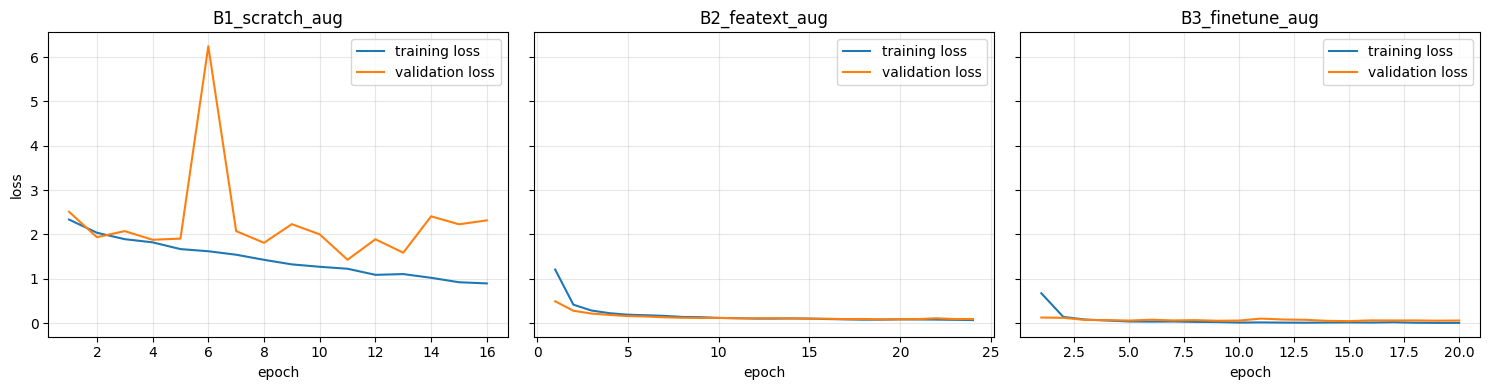

In [6]:
H = pd.DataFrame(histories)
fig, axs = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, name in zip(axs, ['B1_scratch_aug', 'B2_featext_aug', 'B3_finetune_aug']):
    d = H[H.run == name]
    ax.plot(d.epoch, d.train_loss, label='training loss'); ax.plot(d.epoch, d.val_loss, label='validation loss')
    ax.set_title(name); ax.set_xlabel('epoch'); ax.grid(alpha=.3); ax.legend()
axs[0].set_ylabel('loss'); plt.tight_layout(); plt.savefig('learning_curves.png', dpi=200); plt.show()

## 6. B4: dampak augmentasi terhadap overfitting

In [7]:
b4 = df[df.run.isin(['B3_finetune_aug', 'B4_B3_noaug'])][['run','augmentation','train_acc_clean','val_acc','gap_train_val','best_val_loss','gap_loss_val_minus_train','test_acc','test_macro_f1']]
b4.to_csv('b4_augmentation_comparison.csv', index=False); b4

,run,augmentation,train_acc_clean,val_acc,gap_train_val,best_val_loss,gap_loss_val_minus_train,test_acc,test_macro_f1
2,B3_finetune_aug,True,0.999284,0.983333,0.015951,0.043850,0.039981,0.96,0.960157
3,B4_B3_noaug,False,1.000000,0.990000,0.010000,0.036624,0.036522,0.96,0.959947


## 7. Failure analysis (model terbaik menurut validasi, 5 sampai 8 sampel salah prediksi)

Model terbaik (berdasar validasi): B5_efficientnetb0_aug
Salah prediksi B5_efficientnetb0_aug di test set: 7 dari 300


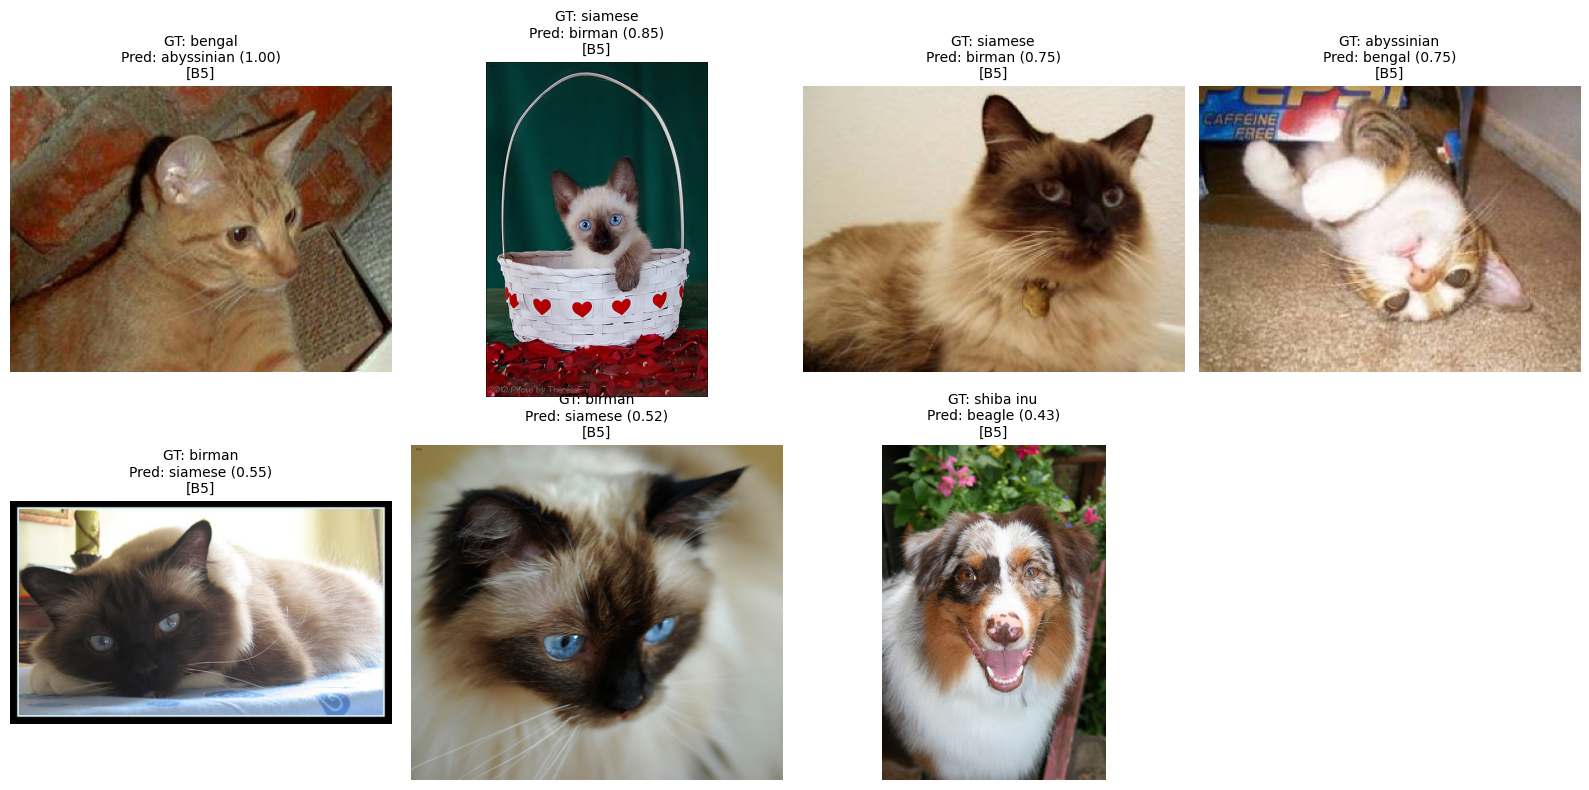

,precision,recall,f1-score,support
abyssinian,0.967,0.967,0.967,30.000
bengal,0.967,0.967,0.967,30.000
birman,0.933,0.933,0.933,30.000
persian,1.000,1.000,1.000,30.000
siamese,0.933,0.933,0.933,30.000
beagle,0.968,1.000,0.984,30.000
pug,1.000,1.000,1.000,30.000
samoyed,1.000,1.000,1.000,30.000
shiba inu,1.000,0.967,0.983,30.000
chihuahua,1.000,1.000,1.000,30.000


In [8]:
cand = df[df.augmentation].sort_values(['val_acc', 'best_val_loss'], ascending=[False, True])   # peringkat berdasarkan VALIDASI
best_name = cand.iloc[0].run; print('Model terbaik (berdasar validasi):', best_name)
_, _, _, te_loader = make_loaders(aug_tf)

def predict_test(name):
    mdl = make_arch(name, pretrained=False); mdl.load_state_dict(states[name]); mdl = mdl.to(DEVICE).eval()
    return collect(mdl, te_loader)

ys, ps, cf, _ = predict_test(best_name)
wrong_best = sorted([(p_te[i], ys[i], ps[i], cf[i], best_name) for i in range(len(ys)) if ys[i] != ps[i]], key=lambda t: -t[3])
print(f'Salah prediksi {best_name} di test set: {len(wrong_best)} dari {len(ys)}')

sel, seen = wrong_best[:8], {w[0] for w in wrong_best[:8]}
if len(sel) < 5:   # model terbaik terlalu bagus: lengkapi dengan error model lain (dicatat di kolom 'model')
    for other in cand.run.tolist()[1:]:
        yo, po, co, _ = predict_test(other)
        extra = sorted([(p_te[i], yo[i], po[i], co[i], other) for i in range(len(yo)) if yo[i] != po[i] and p_te[i] not in seen], key=lambda t: -t[3])
        for e in extra:
            if len(sel) >= 5: break
            sel.append(e); seen.add(e[0])
        if len(sel) >= 5: break
    print(f'Model terbaik hanya salah {len(wrong_best)}; sampel dilengkapi dari model lain (lihat kolom model).')

if sel:
    fig, axs = plt.subplots(2, 4, figsize=(16, 8))
    for ax, (pth, yt, yp, c, mn) in zip(axs.ravel(), sel):
        ax.imshow(Image.open(pth).convert('RGB')); ax.axis('off')
        ax.set_title(f'GT: {SELECTED[yt]}\nPred: {SELECTED[yp]} ({c:.2f})\n[{mn.split("_")[0]}]', fontsize=10)
    for ax in axs.ravel()[len(sel):]: ax.axis('off')
    plt.tight_layout(); plt.savefig('failure_analysis.png', dpi=200); plt.show()
pd.DataFrame([dict(file=os.path.basename(str(a)), model=mn, ground_truth=SELECTED[b], prediction=SELECTED[c_], confidence=round(d, 4),
                   hypothesis='ISI SENDIRI') for a, b, c_, d, mn in sel]).to_csv('failure_samples.csv', index=False)
rep = classification_report(ys, ps, target_names=SELECTED, output_dict=True, zero_division=0)
pd.DataFrame(rep).T.to_csv('per_class_report_best_model.csv'); pd.DataFrame(rep).T.round(3)


## 8. C5 (opsional): Grad-CAM pada layer4, sebelum (B2, backbone beku) dan sesudah fine-tuning (B3)

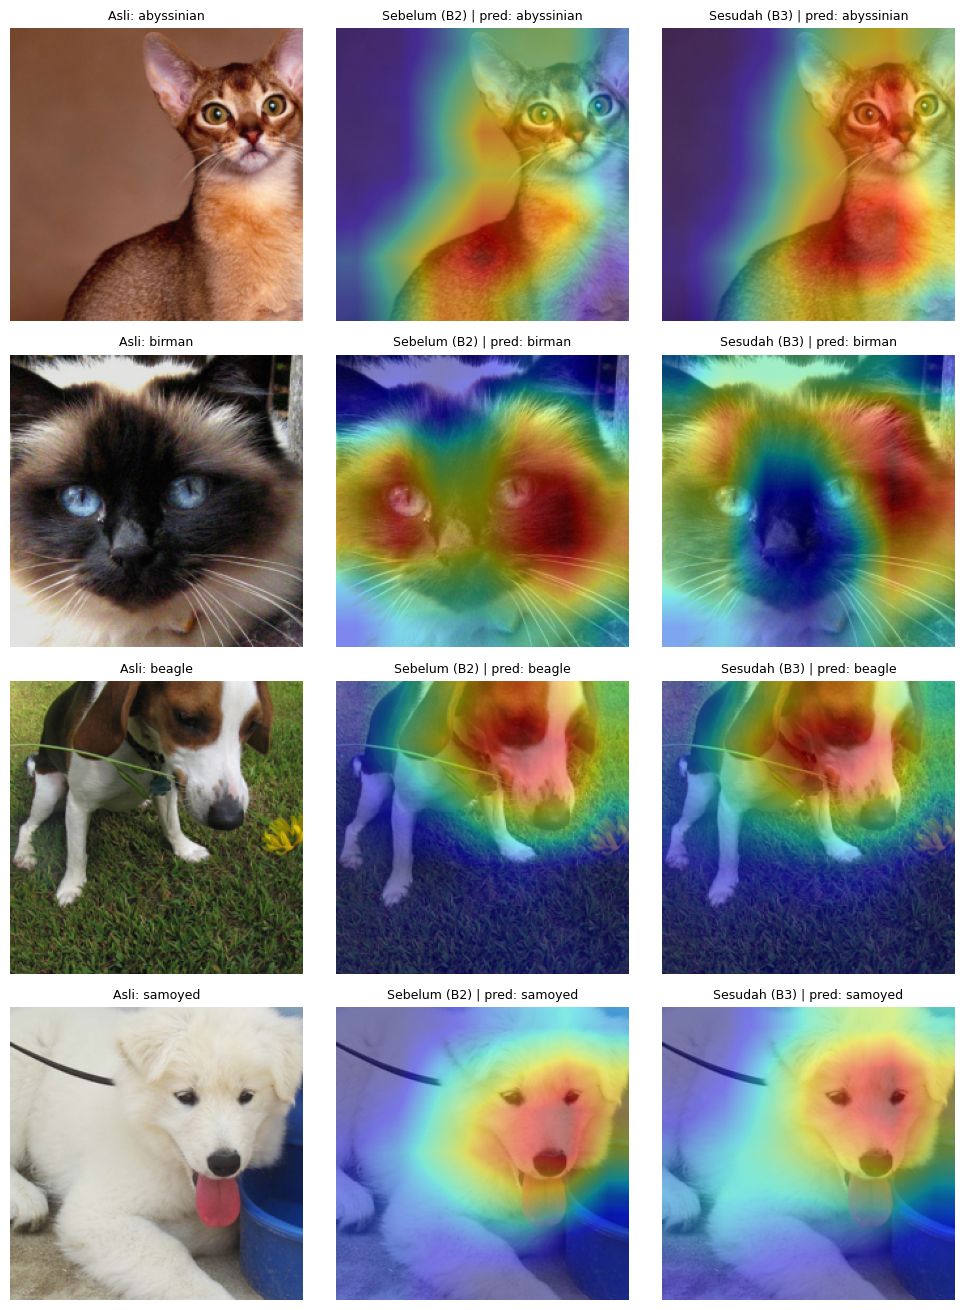

In [9]:
def load_resnet(state):
    m = make_arch('B3', pretrained=False); m.load_state_dict(state); return m.to(DEVICE).eval()

def grad_cam(model, x, target):
    store = {}
    def fwd_hook(mod, inp, out):
        store['act'] = out
        out.register_hook(lambda g: store.__setitem__('grad', g))
    h = model.layer4.register_forward_hook(fwd_hook)
    model.zero_grad(); x = x.clone().requires_grad_(True)   # supaya graf gradien terbentuk meski backbone beku
    out = model(x); pred = out.argmax(1).item(); out[0, target].backward(); h.remove()
    w = store['grad'][0].mean(dim=(1, 2), keepdim=True)
    cam = F.relu((w * store['act'][0]).sum(0, keepdim=True))[None]
    cam = F.interpolate(cam, size=(224, 224), mode='bilinear', align_corners=False)[0, 0]
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return cam.detach().cpu().numpy(), pred

before, after = load_resnet(states['B2_featext_aug']), load_resnet(states['B3_finetune_aug'])
ids = [y_te.index(c) for c in (0, 2, 5, 7)]
mean_t, std_t = torch.tensor(MEAN).view(3, 1, 1), torch.tensor(STD).view(3, 1, 1)
fig, axs = plt.subplots(len(ids), 3, figsize=(10, 3.3 * len(ids)))
for r, i in enumerate(ids):
    x, y = eval_tf(Image.open(p_te[i]).convert('RGB')), y_te[i]
    img = (x * std_t + mean_t).clamp(0, 1).permute(1, 2, 0).numpy()
    axs[r, 0].imshow(img); axs[r, 0].set_title(f'Asli: {SELECTED[y]}', fontsize=9)
    for col, (mdl, tag) in enumerate([(before, 'Sebelum (B2)'), (after, 'Sesudah (B3)')], start=1):
        cam, pred = grad_cam(mdl, x[None].to(DEVICE), y)
        axs[r, col].imshow(img); axs[r, col].imshow(cam, cmap='jet', alpha=0.45)
        axs[r, col].set_title(f'{tag} | pred: {SELECTED[pred]}', fontsize=9)
    for a in axs[r]: a.axis('off')
plt.tight_layout(); plt.savefig('gradcam_layer4.png', dpi=200); plt.show()

## 9. Pengemasan luaran

In [10]:
!pip -q freeze | grep -iE '^(torch|torchvision|scikit-learn|pandas|matplotlib|numpy|pillow)==' > requirements.txt
import zipfile
NIM, NAMA = '2802451655', 'Jos Hwen Sim'     # ganti sebelum menjalankan sel ini

readme = f"""# Tugas 05: Transfer Learning (Oxford-IIIT Pet, 10 kelas)
Nama: {NAMA} | NIM: {NIM} | Seed: {SEED}

## Isi
- `Tugas05_Transfer_Learning.ipynb`: notebook utama (jalankan Run all dari atas)
- `results_summary.csv/json`: ringkasan metrik B1-B5
- `history_per_epoch.csv`: log training/validation per epoch
- `b4_augmentation_comparison.csv`: perbandingan dengan vs tanpa augmentasi
- `failure_samples.csv`, `failure_analysis.png`, `per_class_report_best_model.csv`: failure analysis
- `learning_curves.png`, `gradcam_layer4.png`: visualisasi
- `requirements.txt`: versi library

## Cara menjalankan
1. Buka di Google Colab, runtime GPU (T4).
2. Run all. Dataset diunduh otomatis via torchvision.
3. Seluruh keluaran tersimpan di direktori kerja.

## Protokol
ResNet-18 IMAGENET1K_V1, input 224, AdamW, CrossEntropyLoss, batch {BATCH}, early stopping patience {PATIENCE},
split stratified 70/15/15 (seed {SEED}). Pemilihan model terbaik memakai data validasi, bukan test.
"""
open('README.md', 'w').write(readme)

files = ['results_summary.csv', 'results_summary.json', 'history_per_epoch.csv', 'b4_augmentation_comparison.csv',
         'per_class_report_best_model.csv', 'failure_samples.csv', 'learning_curves.png', 'failure_analysis.png',
         'gradcam_layer4.png', 'requirements.txt', 'README.md']
with zipfile.ZipFile(f'Tugas05_{NIM}_{NAMA}.zip', 'w') as z:
    for f in files:
        if os.path.exists(f): z.write(f)
        else: print('Tidak ditemukan:', f)
print('Tambahkan secara manual: notebook ini (setelah semua sel selesai, dengan output), laporan PDF/MD, tautan GitHub.')
print('Sebelum zip: isi kolom hypothesis di failure_samples.csv dan ganti NIM/NAMA di sel ini.')


Tambahkan secara manual: notebook ini (setelah semua sel selesai, dengan output), laporan PDF/MD, tautan GitHub.
Sebelum zip: isi kolom hypothesis di failure_samples.csv dan ganti NIM/NAMA di sel ini.
